# Hydrodynamic model of the Southern North Sea

Load the data using [MIKE IO](https://dhi.github.io/mikeio) and review it. Data is stored as a dfsu file. Specific points are stored in a dfs0 file. 

In [1]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from datasets.code.helper import get_altimetry_obs, get_wl_point_obs, get_u_v_point_obs

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager

In [2]:
# mr_fldr = "../output_sample/"
mr_fldr = "datasets/output_sample/"

fldr = "datasets/observations/" 
msh = mikeio.open("datasets/input/Mesh_8000_elems_HD_v2.mesh")

## Load data

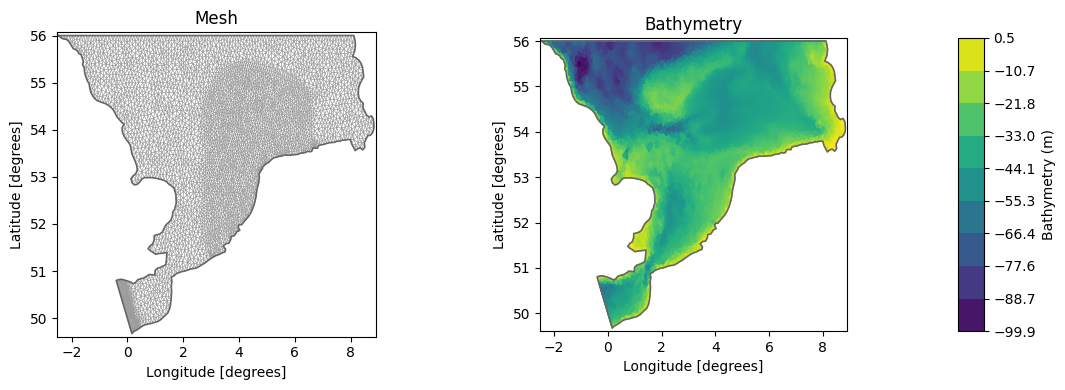

In [3]:
# Load data

dfs = mikeio.open(f"{mr_fldr}Area.dfsu")

geom = dfs.geometry

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()


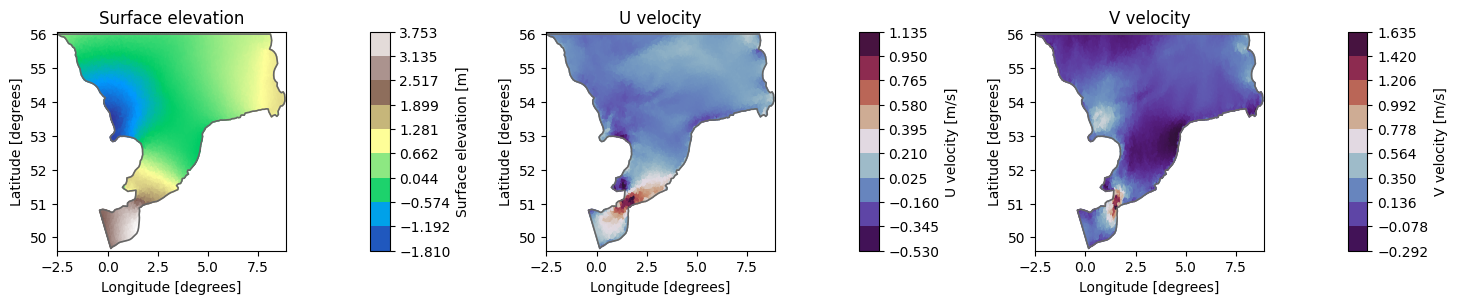

In [4]:
# Extract time series 

ds = dfs.read(time = slice("2022-01-03", "2023-12-31"))

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1], title="U velocity", cmap = "twilight_shifted")
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()

## SHRED from random simulated fixed sensors

In [6]:
# Remove locations with NaNs (same NaNs locations for surface elevation and velocities)

H = ds["Surface elevation"].values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
U = ds["U velocity"].values[:,~np.isnan(ds["U velocity"].values).any(axis=0)]
V = ds["V velocity"].values[:,~np.isnan(ds["V velocity"].values).any(axis=0)]

In [18]:
# Data manager

from pyshred import DataManager

manager = DataManager(
    lags = 48, # 1 day of past measurements for predictions 
    train_size = 0.8,
    val_size = 0.1,
    test_size = 0.1
)

manager.add_data(
    data = H,
    id = "Surface elevation",
    random = 3, # 3 sensors monitoring surface elevation at random locations
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = U,
    id = "U velocity",
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = V,
    id = "V velocity",
    compress = 100 # 100 POD modes for compressive training 
)

train_dataset, val_dataset, test_dataset= manager.prepare()


In [12]:
manager.sensor_summary_df

,data id,sensor_number,type,loc/traj
0,Surface elevation,0,stationary (random),"(8205,)"
1,Surface elevation,1,stationary (random),"(790,)"
2,Surface elevation,2,stationary (random),"(4393,)"


In [13]:
manager.sensor_measurements_df

,Surface elevation-0,Surface elevation-1,Surface elevation-2
0,2.066523,0.457898,0.585220
1,1.338253,0.649758,0.805301
2,0.588034,0.982440,1.044603
3,-0.154516,1.327723,1.234875
4,-0.895682,1.545887,1.334917
...,...,...,...
34938,-1.254984,0.612873,0.437409
34939,-0.526033,0.597068,0.426460
34940,0.230595,0.555951,0.396431
34941,0.944115,0.482235,0.343953


In [ ]:
# SHRED fitting

from pyshred import SHRED

shred = SHRED(sequence_model = "LSTM", decoder_model = "MLP", latent_forecaster = None)

val_errors = shred.fit(train_dataset = train_dataset, val_dataset = val_dataset, num_epochs = 100, verbose = True)

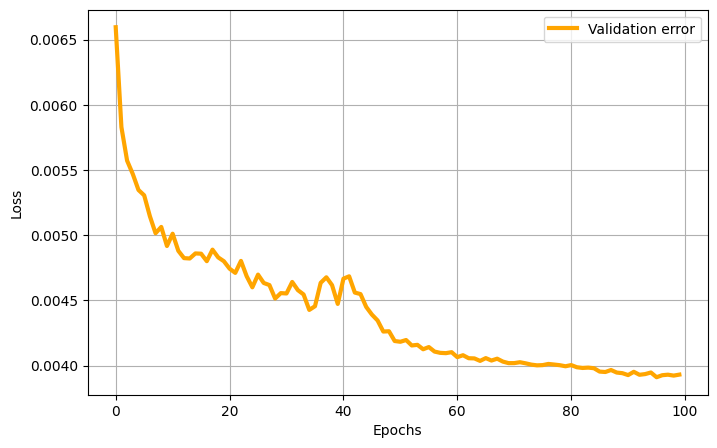

In [ ]:
# Validation loss during training

plt.figure(figsize = (8,5))
plt.plot(val_errors, 'orange', linewidth = 3, label = 'Validation error')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

In [ ]:
# Mean squared errors

train_mse = shred.evaluate(dataset = train_dataset)
val_mse = shred.evaluate(dataset = val_dataset)
test_mse = shred.evaluate(dataset = test_dataset)
print(f"Train MSE: {train_mse:.3f}")
print(f"Val   MSE: {val_mse:.3f}")
print(f"Test  MSE: {test_mse:.3f}")

Train MSE: 0.003
Val   MSE: 0.004
Test  MSE: 0.010


In [22]:
# Reconstruction from test sensors

from pyshred import SHREDEngine

engine = SHREDEngine(manager, shred)
test_latent_from_sensors = engine.sensor_to_latent(manager.test_sensor_measurements)
test_reconstruction = engine.decode(test_latent_from_sensors)

In [ ]:
# Build datasets with SHRED reconstructions and errors (filling NaN locations for plotting)

times_test = ds.time[-test_reconstruction["Surface elevation"].shape[0]:]

H_reconstruction = np.full((test_reconstruction["Surface elevation"].shape[0], ds["Surface elevation"].values.shape[1]), np.nan)
H_reconstruction[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)] = test_reconstruction["Surface elevation"]

U_reconstruction = np.full((test_reconstruction["U velocity"].shape[0], ds["U velocity"].values.shape[1]), np.nan)
U_reconstruction[:,~np.isnan(ds["U velocity"].values).any(axis=0)] = test_reconstruction["U velocity"]

V_reconstruction = np.full((test_reconstruction["V velocity"].shape[0], ds["V velocity"].values.shape[1]), np.nan)
V_reconstruction[:,~np.isnan(ds["V velocity"].values).any(axis=0)] = test_reconstruction["V velocity"]

ds_shred = mikeio.Dataset(
    data = [H_reconstruction, U_reconstruction, V_reconstruction],
    geometry = geom,
    time = times_test,
    items = ds.items,
)

ds_error = mikeio.Dataset(
    data = [np.sqrt((ds["Surface elevation"].sel(time = times_test).values - ds_shred["Surface elevation"].values)**2),
            np.sqrt((ds["U velocity"].sel(time = times_test).values - ds_shred["U velocity"].values)**2),
            np.sqrt((ds["V velocity"].sel(time = times_test).values - ds_shred["V velocity"].values)**2)],
    geometry = geom,
    time = times_test,
    items = ds.items,
)

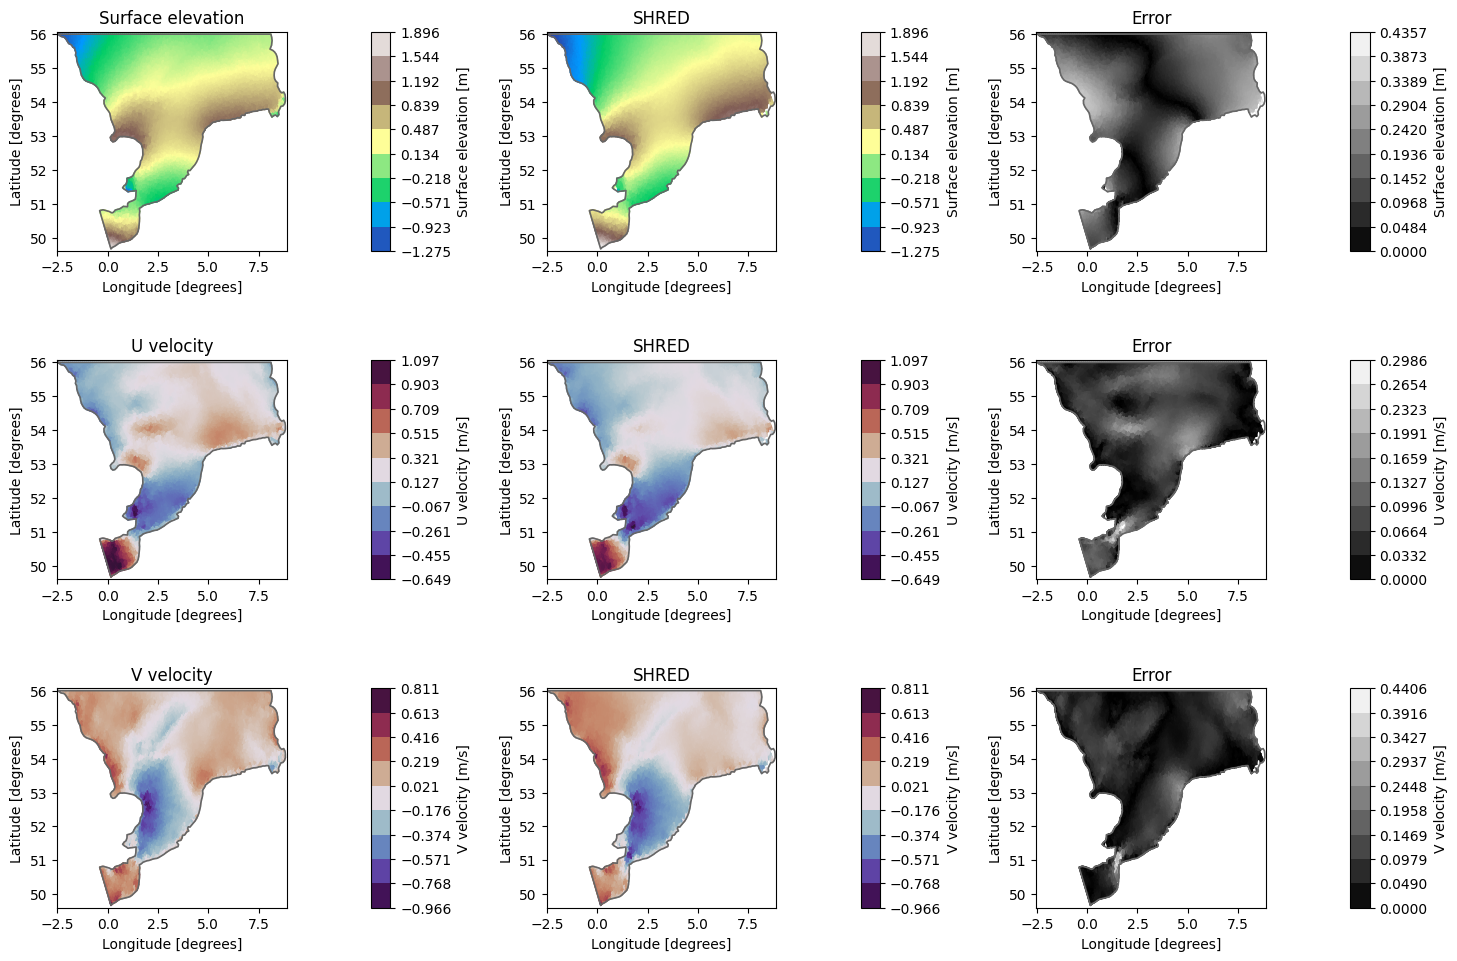

In [ ]:
# Qualitative comparison

plot_time = ds_shred.time[-1]
fig,axs = plt.subplots(3, 3, figsize=(15,10))
vmin = min(np.nanmin(ds["Surface elevation"].sel(time=plot_time).values), np.nanmin(ds_shred["Surface elevation"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["Surface elevation"].sel(time=plot_time).values), np.nanmax(ds_shred["Surface elevation"].sel(time=plot_time).values))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,0], title="Surface elevation", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_shred["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,1], title="SHRED", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_error["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["U velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["U velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["U velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["U velocity"].sel(time=plot_time).values))
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1,0], title="U velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["U velocity"].sel(time=plot_time).plot(ax=axs[1,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["U velocity"].sel(time=plot_time).plot(ax=axs[1,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["V velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["V velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["V velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["V velocity"].sel(time=plot_time).values))
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2,0], title="V velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["V velocity"].sel(time=plot_time).plot(ax=axs[2,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["V velocity"].sel(time=plot_time).plot(ax=axs[2,2], title="Error", cmap = "gray")

plt.tight_layout()
plt.show()

## SHRED from in-situ water level data (fixed sensors)


<Axes: >

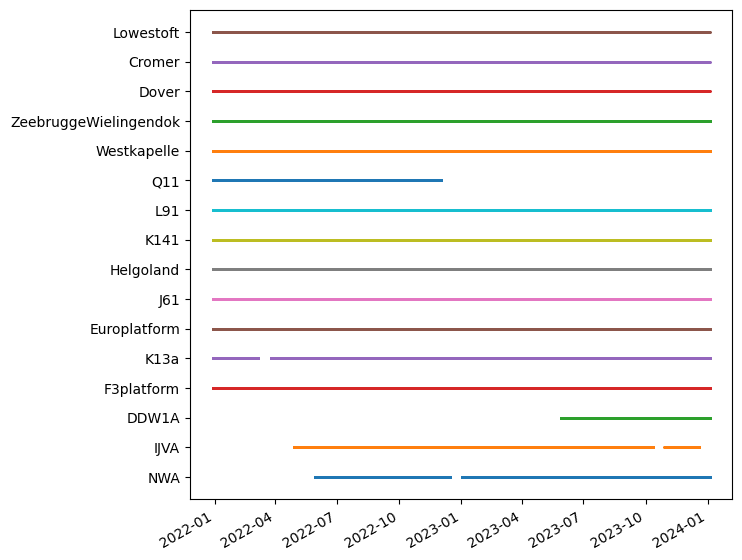

In [5]:
# Temporal coverage of in-situ stations

wllist = get_wl_point_obs()

ms.plotting.temporal_coverage(wllist)

Text(0.5, 1.0, 'Water level stations')

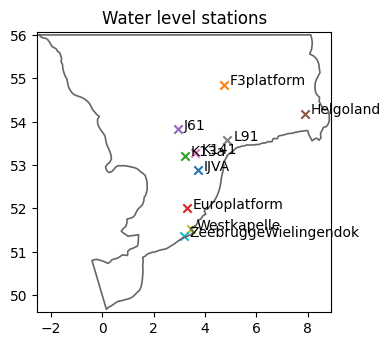

In [6]:
# Select stations with full temporal coverage

stations = []
for i in range(len(wllist)):
    if ds.time.isin(wllist[i].time).all():
        stations.append(wllist[i])

ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (4,4));
plt.tight_layout()
plt.title("Water level stations")

In [7]:
# Extract water level measurements

measurements = np.zeros((ds.time.shape[0], len(stations)))

for i in range(len(stations)):
    
    stn_data = pd.read_csv(fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"][ds.time.strftime("%Y-%m-%d %H:%M:%S")].values

In [8]:
# Remove locations with NaNs (same NaNs locations for surface elevation and velocities)

H = ds["Surface elevation"].values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
U = ds["U velocity"].values[:,~np.isnan(ds["U velocity"].values).any(axis=0)]
V = ds["V velocity"].values[:,~np.isnan(ds["V velocity"].values).any(axis=0)]

In [9]:
H.shape,U.shape,V.shape,measurements.shape

((337, 8551), (337, 8551), (337, 8551), (337, 10))

In [11]:
# Data manager

manager = DataManager(
    lags = 48, # 1 day of past measurements for predictions 
    train_size = 0.8,
    val_size = 0.1,
    test_size = 0.1
)

manager.add_data(
    data = H,
    id = "Surface elevation",
    measurements = measurements,
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = U,
    id = "U velocity",
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = V,
    id = "V velocity",
    compress = 100 # 100 POD modes for compressive training 
)

train_dataset, val_dataset, test_dataset= manager.prepare()


In [11]:
manager.sensor_summary_df

,data id,sensor_number,type,loc/traj
0,Surface elevation,0,measurement,None
1,Surface elevation,1,measurement,None
2,Surface elevation,2,measurement,None
3,Surface elevation,3,measurement,None
4,Surface elevation,4,measurement,None


In [12]:
manager.sensor_measurements_df

,Surface elevation-0,Surface elevation-1,Surface elevation-2,Surface elevation-3,Surface elevation-4
0,-0.6245,1.3441,-0.1241,2.4306,2.5258
1,-0.6345,1.1341,-0.2841,2.4506,2.4858
2,-0.5945,0.8641,-0.3941,2.3106,2.3158
3,-0.4645,0.6641,-0.4541,2.1206,2.0758
4,-0.2845,0.4041,-0.4441,1.8906,1.7658
...,...,...,...,...,...
34938,0.7181,-0.5759,0.7559,-0.7594,-1.0542
34939,0.7181,-0.2959,0.8359,-0.8094,-1.0142
34940,0.6281,0.0041,0.8859,-0.7594,-0.9142
34941,0.5381,0.3141,0.9059,-0.6694,-0.7442


In [13]:
# SHRED fitting

from pyshred import SHRED

shred = SHRED(sequence_model = "LSTM", decoder_model = "MLP", latent_forecaster = None)

val_errors = shred.fit(train_dataset = train_dataset, val_dataset = val_dataset, num_epochs = 100, verbose = True)

Fitting SHRED...
Epoch 1: Average training loss = 0.010247
Validation MSE (epoch 1): 0.006462
Epoch 2: Average training loss = 0.006270
Validation MSE (epoch 2): 0.005775
Epoch 3: Average training loss = 0.005850
Validation MSE (epoch 3): 0.005594
Epoch 4: Average training loss = 0.005694
Validation MSE (epoch 4): 0.005419
Epoch 5: Average training loss = 0.005455
Validation MSE (epoch 5): 0.005300
Epoch 6: Average training loss = 0.005379
Validation MSE (epoch 6): 0.005275
Epoch 7: Average training loss = 0.005331
Validation MSE (epoch 7): 0.005127
Epoch 8: Average training loss = 0.005258
Validation MSE (epoch 8): 0.005157
Epoch 9: Average training loss = 0.005217
Validation MSE (epoch 9): 0.005105
Epoch 10: Average training loss = 0.005148
Validation MSE (epoch 10): 0.005191
Epoch 11: Average training loss = 0.005097
Validation MSE (epoch 11): 0.005014
Epoch 12: Average training loss = 0.005118
Validation MSE (epoch 12): 0.004945
Epoch 13: Average training loss = 0.005032
Validation

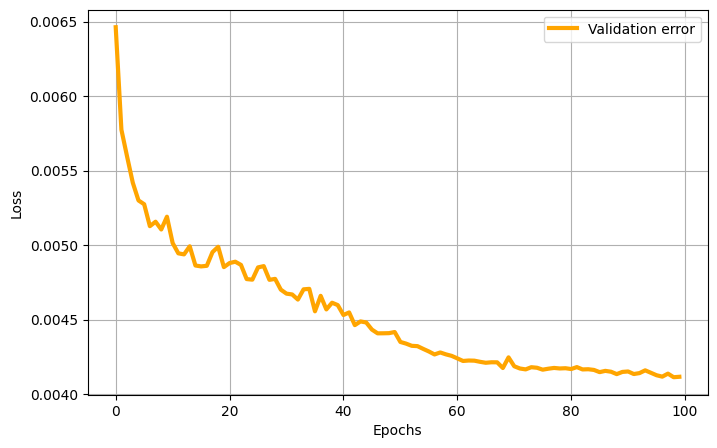

In [14]:
# Validation loss during training

plt.figure(figsize = (8,5))
plt.plot(val_errors, 'orange', linewidth = 3, label = 'Validation error')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

In [15]:
# Mean squared errors

train_mse = shred.evaluate(dataset = train_dataset)
val_mse = shred.evaluate(dataset = val_dataset)
test_mse = shred.evaluate(dataset = test_dataset)
print(f"Train MSE: {train_mse:.3f}")
print(f"Val   MSE: {val_mse:.3f}")
print(f"Test  MSE: {test_mse:.3f}")

Train MSE: 0.004
Val   MSE: 0.004
Test  MSE: 0.010


In [16]:
# Reconstruction from test sensors

from pyshred import SHREDEngine

engine = SHREDEngine(manager, shred)
test_latent_from_sensors = engine.sensor_to_latent(manager.test_sensor_measurements)
test_reconstruction = engine.decode(test_latent_from_sensors)

In [17]:
# Build datasets with SHRED reconstructions and errors (filling NaN locations for plotting)

times_test = ds.time[-test_reconstruction["Surface elevation"].shape[0]:]

H_reconstruction = np.full((test_reconstruction["Surface elevation"].shape[0], ds["Surface elevation"].values.shape[1]), np.nan)
H_reconstruction[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)] = test_reconstruction["Surface elevation"]

U_reconstruction = np.full((test_reconstruction["U velocity"].shape[0], ds["U velocity"].values.shape[1]), np.nan)
U_reconstruction[:,~np.isnan(ds["U velocity"].values).any(axis=0)] = test_reconstruction["U velocity"]

V_reconstruction = np.full((test_reconstruction["V velocity"].shape[0], ds["V velocity"].values.shape[1]), np.nan)
V_reconstruction[:,~np.isnan(ds["V velocity"].values).any(axis=0)] = test_reconstruction["V velocity"]

ds_shred = mikeio.Dataset(
    data = [H_reconstruction, U_reconstruction, V_reconstruction],
    geometry = geom,
    time = times_test,
    items = ds.items,
)

ds_error = mikeio.Dataset(
    data = [np.sqrt((ds["Surface elevation"].sel(time = times_test).values - ds_shred["Surface elevation"].values)**2),
            np.sqrt((ds["U velocity"].sel(time = times_test).values - ds_shred["U velocity"].values)**2),
            np.sqrt((ds["V velocity"].sel(time = times_test).values - ds_shred["V velocity"].values)**2)],
    geometry = geom,
    time = times_test,
    items = ds.items,
)

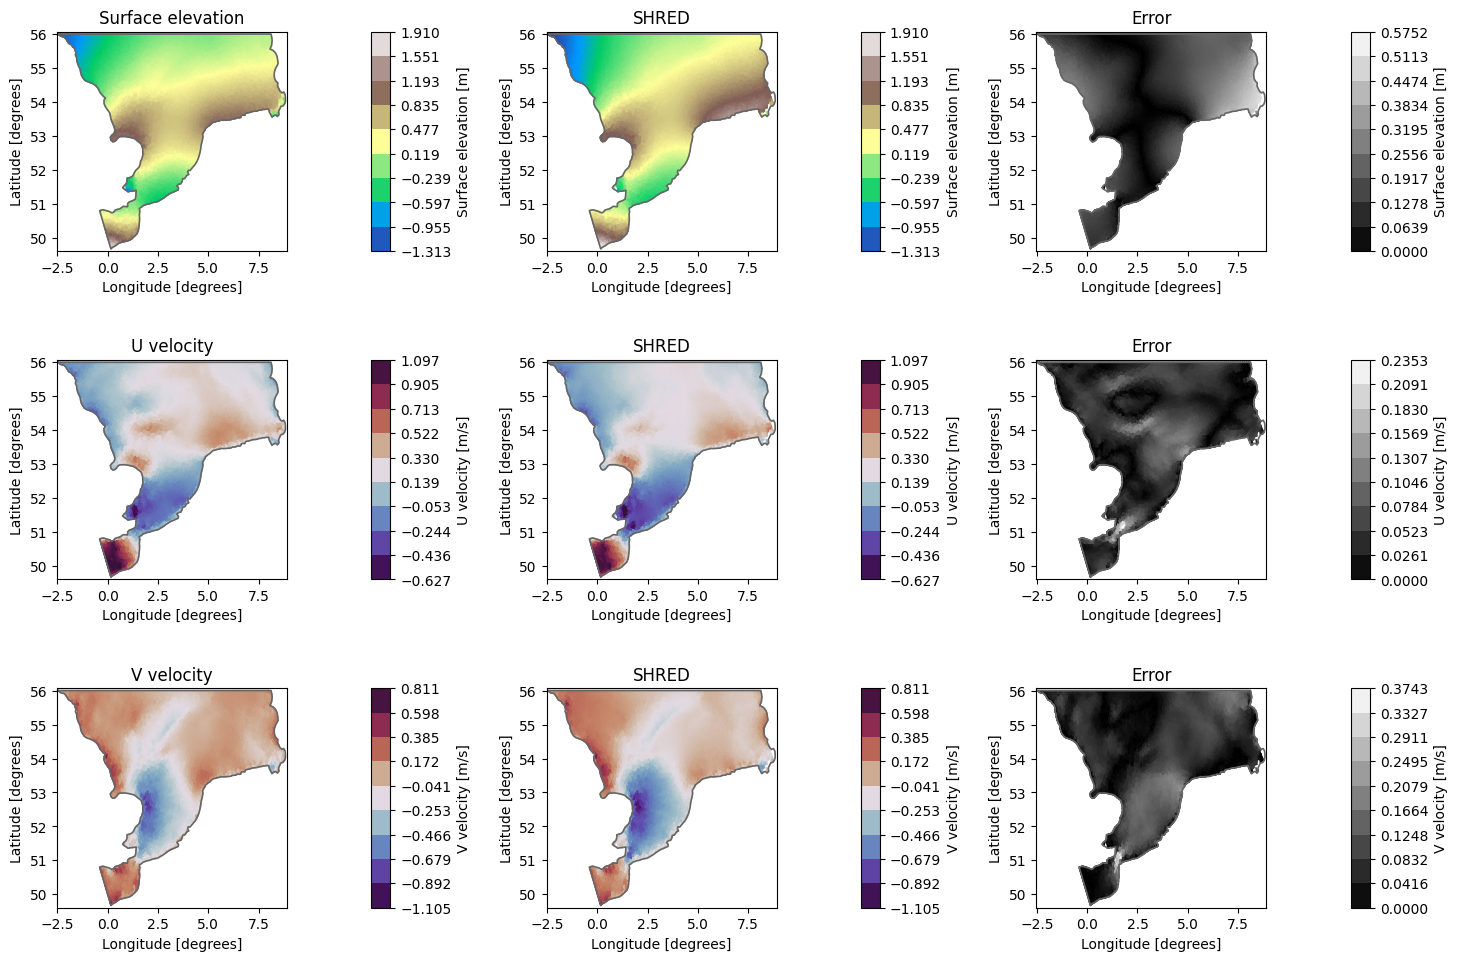

<Figure size 640x480 with 0 Axes>

In [ ]:
# Qualitative comparison

plot_time = ds_shred.time[-1]
fig,axs = plt.subplots(3, 3, figsize=(15,10))
vmin = min(np.nanmin(ds["Surface elevation"].sel(time=plot_time).values), np.nanmin(ds_shred["Surface elevation"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["Surface elevation"].sel(time=plot_time).values), np.nanmax(ds_shred["Surface elevation"].sel(time=plot_time).values))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,0], title="Surface elevation", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_shred["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,1], title="SHRED", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_error["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["U velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["U velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["U velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["U velocity"].sel(time=plot_time).values))
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1,0], title="U velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["U velocity"].sel(time=plot_time).plot(ax=axs[1,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["U velocity"].sel(time=plot_time).plot(ax=axs[1,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["V velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["V velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["V velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["V velocity"].sel(time=plot_time).values))
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2,0], title="V velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["V velocity"].sel(time=plot_time).plot(ax=axs[2,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["V velocity"].sel(time=plot_time).plot(ax=axs[2,2], title="Error", cmap = "gray")

plt.tight_layout()
plt.show()